# EDA — Lego Fusion Battle Towers pieces
Class balance, image quality, auto piece boxes (GrabCut on plain table), piece color separability.
`eda/stats.csv` (one row per image, incl. normalized boxes) is reused later for Faster R-CNN / YOLO labels.

**What this notebook does.** A first look at the dataset (exploratory data analysis): how many photos each piece and color has, image size, brightness and sharpness, automatic brick boxes made with GrabCut, and whether the piece colors can be told apart by their average color alone.

**Needs:** `data/labels.csv`, `dataset/`. **Writes:** `eda/stats.csv` (one row per photo).

Imports and the photo list. Photos are analysed at 1/16 size, because GrabCut gets slow on big images.

In [9]:
import os
if os.path.basename(os.getcwd()) == 'notebooks': os.chdir('..')   # all paths below are from the repo root
import csv, os
from collections import Counter
from multiprocessing import Pool
import cv2, numpy as np
import matplotlib.pyplot as plt

OUT = 'eda'
SCALE = 16  # analyse at 1/16 resolution (252x189): GrabCut cost grows fast with size; box error ~16px at full res
os.makedirs(OUT, exist_ok=True)
rows = list(csv.DictReader(open('data/labels.csv')))
len(rows)

6492

**Result:** 6492 photos are listed.

## Per-image analysis
Brightness, sharpness (Laplacian variance), piece box + median piece color in Lab.

In [10]:
def analyse(row):
    img = cv2.imread(row['path'], cv2.IMREAD_REDUCED_COLOR_8)  # applies EXIF rotation
    img = cv2.resize(img, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
    h, w = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    # shortcut: GrabCut seeded with central 80% rect assumes one piece near the middle; fine for these shots, not for built structures
    mask = np.zeros((h, w), np.uint8)
    mx, my = int(0.1 * w), int(0.1 * h)
    cv2.grabCut(img, mask, (mx, my, w - 2 * mx, h - 2 * my), np.zeros((1, 65)), np.zeros((1, 65)), 2, cv2.GC_INIT_WITH_RECT)
    fg = np.isin(mask, (cv2.GC_FGD, cv2.GC_PR_FGD)).astype(np.uint8)
    n, lab, st, _ = cv2.connectedComponentsWithStats(fg)
    res = dict(path=row['path'], element_id=row['element_id'], part_num=row['part_num'], color=row['lego_color_id'],
               w=w * SCALE, h=h * SCALE, brightness=gray.mean(), blur=cv2.Laplacian(gray, cv2.CV_64F).var())
    if n > 1:
        k = 1 + st[1:, cv2.CC_STAT_AREA].argmax()
        x, y, bw, bh, a = st[k]
        L, A, B = np.median(cv2.cvtColor(img, cv2.COLOR_BGR2LAB)[lab == k], axis=0)
        res.update(x0=x / w, y0=y / h, x1=(x + bw) / w, y1=(y + bh) / h, area=a / (w * h), L=L, A=A, B=B)
    return res

# test on a few before the full run
[analyse(r) for r in rows[:3]]

[{'path': 'dataset/4286_192_4211197/IMG_0001.JPG',
  'element_id': '4211197',
  'part_num': '4286',
  'color': '192',
  'w': 4032,
  'h': 3024,
  'brightness': np.float64(146.83988410178887),
  'blur': np.float64(22.688815967765606),
  'x0': np.float64(0.38492063492063494),
  'y0': np.float64(0.2275132275132275),
  'x1': np.float64(0.6825396825396826),
  'y1': np.float64(0.6349206349206349),
  'area': np.float64(0.09975224657764341),
  'L': np.float64(163.0),
  'A': np.float64(128.0),
  'B': np.float64(137.0)},
 {'path': 'dataset/4286_192_4211197/IMG_0002.JPG',
  'element_id': '4211197',
  'part_num': '4286',
  'color': '192',
  'w': 4032,
  'h': 3024,
  'brightness': np.float64(148.69368858654573),
  'blur': np.float64(21.993854842679347),
  'x0': np.float64(0.3888888888888889),
  'y0': np.float64(0.41798941798941797),
  'x1': np.float64(0.6309523809523809),
  'y1': np.float64(0.6507936507936508),
  'area': np.float64(0.04146720416561686),
  'L': np.float64(29.0),
  'A': np.float64(13

**Result:** The output shows the result on the first 3 photos: a box, brightness, sharpness and a median Lab color per photo, as a check before the full run.

Run the analysis on every photo in parallel and save it to `eda/stats.csv`.

In [11]:
%%time
with Pool() as p:  # fork on Linux, so notebook-defined analyse() works
    stats = p.map(analyse, rows, chunksize=16)
keys = sorted({k for s in stats for k in s})
with open(f'{OUT}/stats.csv', 'w', newline='') as fh:
    w = csv.DictWriter(fh, keys); w.writeheader(); w.writerows(stats)
boxed = [s for s in stats if 'area' in s]
print(f'boxed {len(boxed)}/{len(stats)}')

boxed 6486/6492
CPU times: user 356 ms, sys: 204 ms, total: 560 ms
Wall time: 2min 38s


**Result:** 6486 of 6492 photos got a box. Run time is about 2.5 minutes.

## Class balance

images per element: 41 classes, min 71, max 325, median 128
images per shape: 25 classes, min 71, max 877, median 210
images per LEGO color ID: 8 classes, min 97, max 1907, median 1095


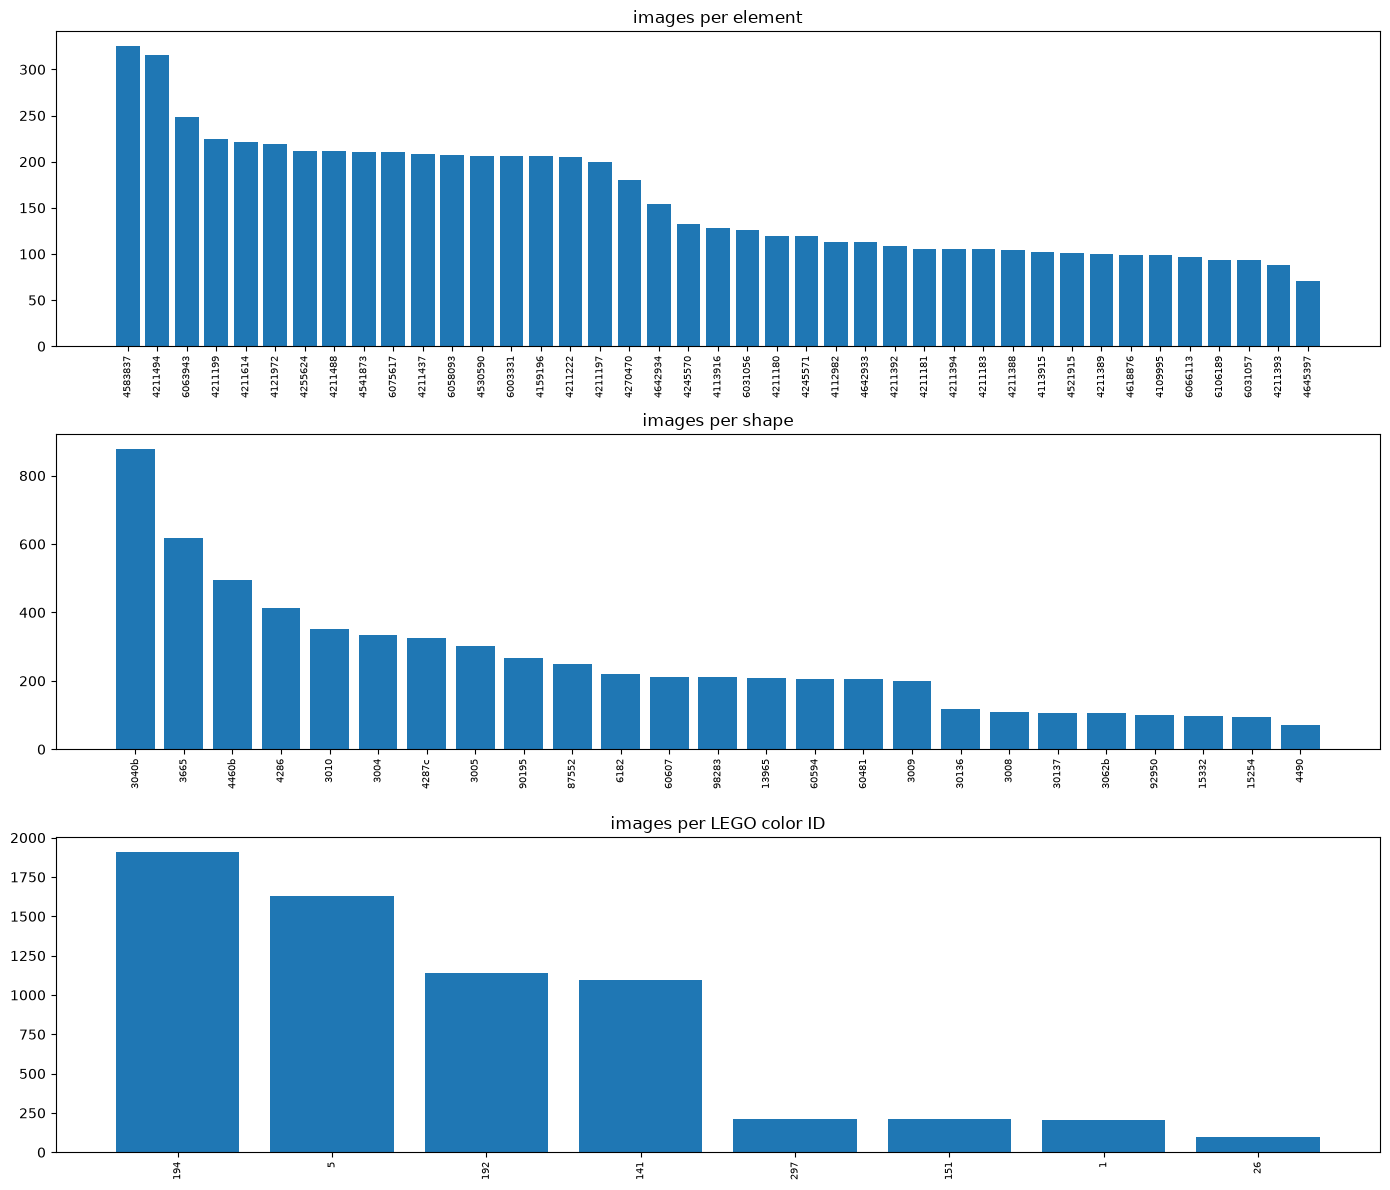

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
for ax, (col, t) in zip(axes, (('element_id', 'images per element'), ('part_num', 'images per shape'), ('color', 'images per LEGO color ID'))):
    c = Counter(s[col] for s in stats)
    k, v = zip(*c.most_common())
    ax.bar(range(len(k)), v); ax.set_xticks(range(len(k)), k, rotation=90, fontsize=7); ax.set_title(t)
    print(f'{t}: {len(c)} classes, min {min(v)}, max {max(v)}, median {sorted(v)[len(v)//2]}')
plt.tight_layout(); plt.show()

**Result:** 41 elements with 71-325 photos each (median 128), 25 shapes and 8 colors. The data is imbalanced, but every class has at least 71 photos.

## Image size, piece size, sharpness, brightness

image sizes: Counter({(4032, 3024): 6492})
piece area % of frame: p5 1.36  median 11.80  p95 31.18
sharpness p5 22 median 58 | brightness p5 140 median 146


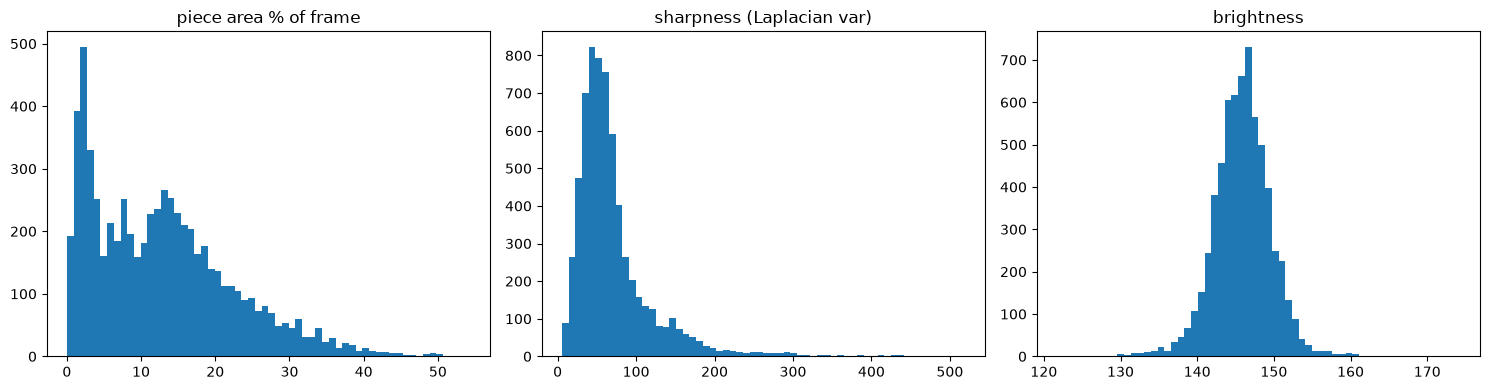

In [13]:
print('image sizes:', Counter((s['w'], s['h']) for s in stats))
area = np.array([s['area'] for s in boxed])
blur = np.array([s['blur'] for s in stats]); br = np.array([s['brightness'] for s in stats])
print('piece area %% of frame: p5 %.2f  median %.2f  p95 %.2f' % tuple(100 * np.percentile(area, [5, 50, 95])))
print('sharpness p5 %.0f median %.0f | brightness p5 %.0f median %.0f' % (*np.percentile(blur, [5, 50]), *np.percentile(br, [5, 50])))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(100 * area, 60); ax[0].set_title('piece area % of frame')
ax[1].hist(blur, 60); ax[1].set_title('sharpness (Laplacian var)')
ax[2].hist(br, 60); ax[2].set_title('brightness')
plt.tight_layout(); plt.show()

**Result:** Every photo is 4032x3024. The brick usually covers about 12% of the frame (5-95%: 1.4-31%). Brightness is very even, and sharpness varies more.

## Auto-box sanity check
2 random images per element. If boxes are good, they become detector labels.

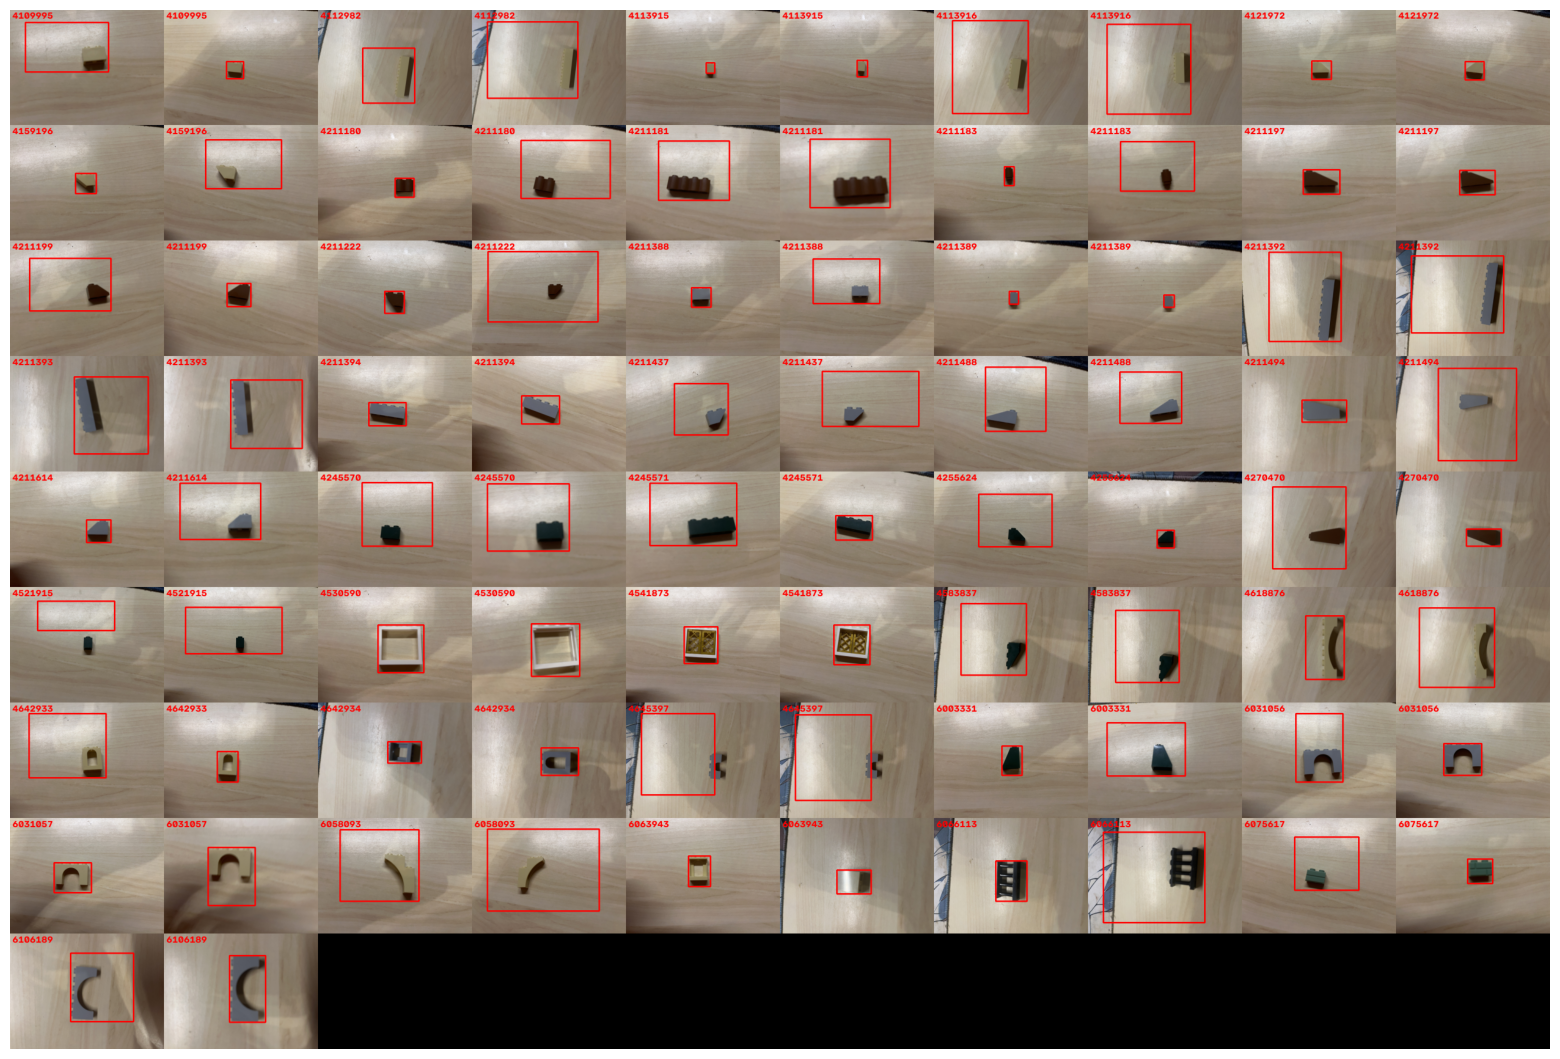

In [14]:
def show(sel, cols=10):
    tiles = []
    for s in sel:
        im = cv2.imread(s['path'], cv2.IMREAD_REDUCED_COLOR_8)
        H, W = im.shape[:2]
        if 'x0' in s:
            cv2.rectangle(im, (int(s['x0'] * W), int(s['y0'] * H)), (int(s['x1'] * W), int(s['y1'] * H)), (0, 0, 255), 3)
        cv2.putText(im, s['element_id'], (8, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
        tiles.append(cv2.resize(im, (252, 189)))
    tiles += [np.zeros_like(tiles[0])] * (-len(tiles) % cols)
    sheet = np.vstack([np.hstack(tiles[i:i + cols]) for i in range(0, len(tiles), cols)])
    plt.figure(figsize=(20, 20 * sheet.shape[0] / sheet.shape[1])); plt.imshow(sheet[..., ::-1]); plt.axis('off'); plt.show()

rng = np.random.default_rng(0)
show([s for e in sorted({s['element_id'] for s in boxed}) for s in rng.choice([s for s in boxed if s['element_id'] == e], 2, replace=False)])

**Result:** Two random photos per element with their GrabCut box. If the boxes sit on the bricks, they are good enough as rough detector labels.

## Worst cases: blurriest, darkest, biggest/smallest boxes

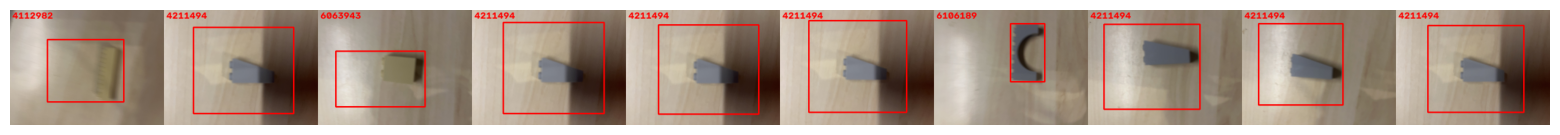

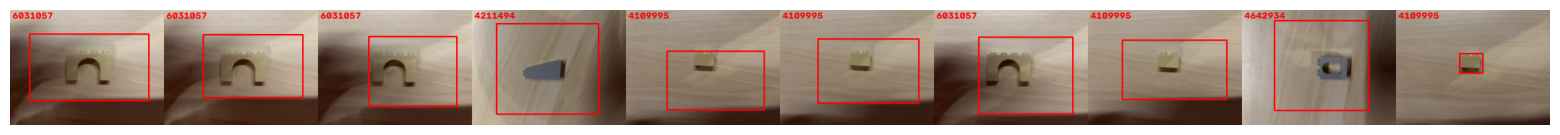

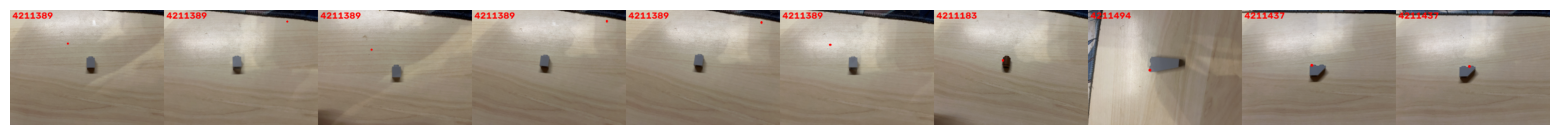

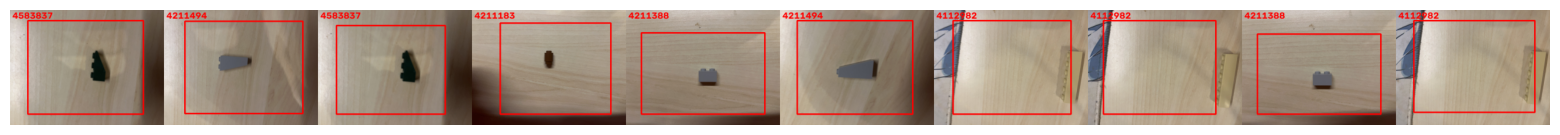

In [15]:
show(sorted(stats, key=lambda s: s['blur'])[:10])
show(sorted(stats, key=lambda s: s['brightness'])[:10])
show(sorted(boxed, key=lambda s: s['area'])[:10])
show(sorted(boxed, key=lambda s: -s['area'])[:10])

**Result:** The 10 blurriest, darkest, smallest-box and biggest-box photos. This is where the box method fails, mostly on very small or low-contrast bricks.

## Color separability
Median piece color (Lab a*/b*), colored by true LEGO color ID. Tight separate clusters → nearest-centroid color is enough, no color net.

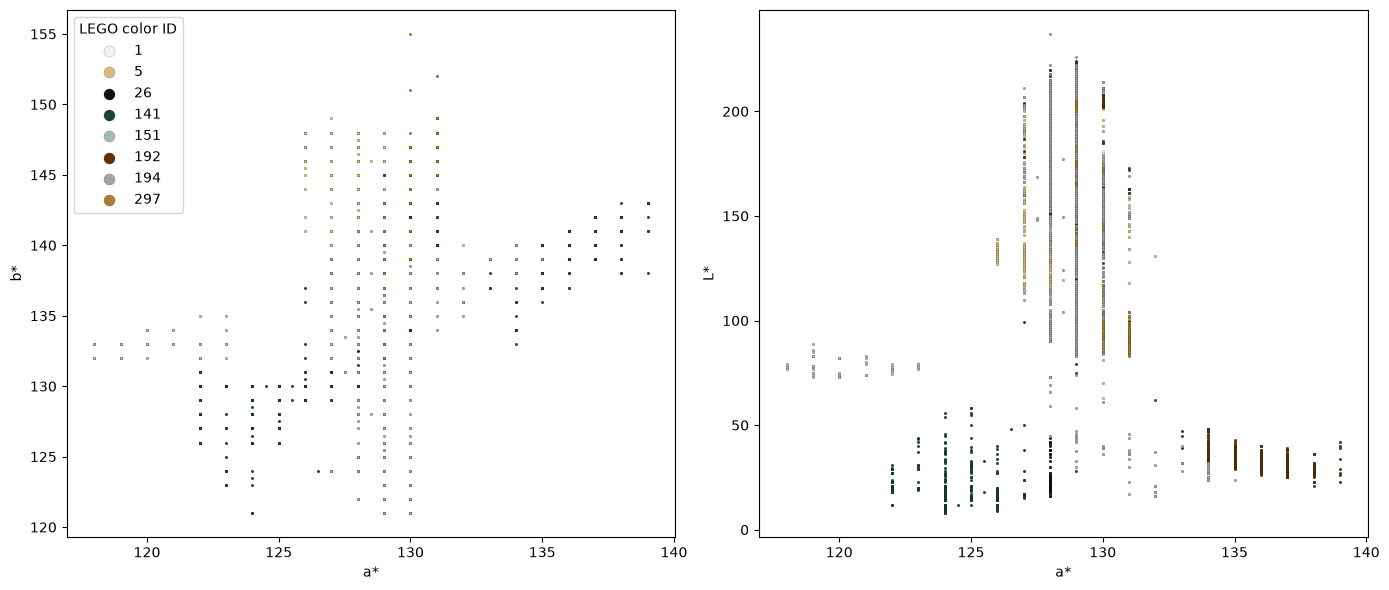

nearest-centroid color acc: 0.111
1 [(np.str_('1'), 114), (np.str_('5'), 88), (np.str_('151'), 4)]
141 [(np.str_('1'), 457), (np.str_('26'), 388), (np.str_('5'), 124)]
151 [(np.str_('1'), 111), (np.str_('26'), 57), (np.str_('5'), 24)]
192 [(np.str_('1'), 445), (np.str_('26'), 367), (np.str_('5'), 171)]
194 [(np.str_('1'), 758), (np.str_('297'), 458), (np.str_('5'), 222)]
26 [(np.str_('26'), 76), (np.str_('1'), 21)]
297 [(np.str_('297'), 163), (np.str_('1'), 30), (np.str_('194'), 6)]
5 [(np.str_('1'), 649), (np.str_('192'), 395), (np.str_('5'), 205)]


In [16]:
swatch = {'1': '#f2f2f2', '5': '#d9bb7b', '26': '#111111', '141': '#184632', '151': '#a0bcac',
          '192': '#5f3109', '194': '#a0a5a9', '297': '#aa7f2e'}
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for cid, hexc in swatch.items():
    p = np.array([(s['A'], s['B'], s['L']) for s in boxed if s['color'] == cid])
    if len(p):
        ax[0].scatter(p[:, 0], p[:, 1], s=4, c=hexc, edgecolors='k', linewidths=0.1, label=cid)
        ax[1].scatter(p[:, 0], p[:, 2], s=4, c=hexc, edgecolors='k', linewidths=0.1, label=cid)
ax[0].set(xlabel='a*', ylabel='b*'); ax[1].set(xlabel='a*', ylabel='L*')
ax[0].legend(title='LEGO color ID', markerscale=4); plt.tight_layout(); plt.show()

# nearest-centroid accuracy (train=val here, so optimistic upper bound)
X = np.array([(s['L'], s['A'], s['B']) for s in boxed]); y = np.array([s['color'] for s in boxed])
cls = sorted(set(y)); C = np.array([X[y == c].mean(0) for c in cls])
pred = np.array(cls)[((X[:, None] - C) ** 2).sum(-1).argmin(1)]
print('nearest-centroid color acc: %.3f' % (pred == y).mean())
for c in cls:
    print(c, Counter(pred[y == c]).most_common(3))

**Result:** The color clusters overlap heavily, and nearest-centroid color accuracy is only 11%. GrabCut's color sample includes too much table and shadow, so color needs a better brick mask (later solved with the real boxes and the lookup).

## Conclusion
The dataset is clean and consistent: one camera, one size, even lighting, and at least 71 photos per element. The weak spots are small bricks (some cover about 1% of the frame) and color. A plain average of the GrabCut region can't tell the colors apart (11% accuracy), so later notebooks measure color from the hand-checked boxes instead. `eda/stats.csv` keeps the per-photo numbers for reuse.